# 04 · Explainable AI: five attribution methods, sanity checks and faithfulness

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Rishabh-bgp/brain-tumor-mri-classification/blob/main/notebooks/04_explainable_ai.ipynb)

Grad-CAM, Grad-CAM++, Integrated Gradients (Captum), occlusion sensitivity and KernelSHAP on SLIC superpixels, checked with the cascading model-parameter randomisation test (Adebayo et al., 2018) and scored with deletion / insertion AUC (Petsiuk et al., 2018). Set `FORCE_XAI = True` to recompute the full study (about 20–30 min on CPU).

*Rishabh Aryan · M.Tech (AI & Data Science), IIIT Bhagalpur. Research and education code, not a medical device.*

In [1]:
# --- Setup: works locally (repo checkout) and on Google Colab ---
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("brain-tumor-mri-classification"):
        subprocess.run(["git", "clone", "-q", "https://github.com/Rishabh-bgp/brain-tumor-mri-classification.git"], check=True)
    os.chdir("brain-tumor-mri-classification")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "kagglehub", "imagehash", "captum",
                    "onnx", "onnxruntime", "scikit-image"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
print("working directory:", os.getcwd())

working directory: /workspace/brain-tumor-mri/repo


In [2]:
import torch
print("PyTorch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU (Colab: Runtime > Change runtime type > GPU for faster training)")

PyTorch 2.15.0+cpu | CUDA available: False
Running on CPU (Colab: Runtime > Change runtime type > GPU for faster training)


In [3]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from pathlib import Path
from btmri import CLASSES, CLASS_LABELS
from btmri.model import build_model
from btmri.xai import GreyModel, explain, METHODS, METHOD_LABELS, deletion_insertion
from btmri.data import download_dataset, load_gray_square
model = build_model(pretrained=False)
model.load_state_dict(torch.load("results/runs/clean/best.pt", map_location="cpu")); model.eval()
gm = GreyModel(model).eval()
root = download_dataset()
pred = pd.read_csv("results/predictions/clean_test_predictions.csv")

### Live example: all five methods on one test slice per class

/tmp/ipykernel_332739/48885870.py:4: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)
  x = torch.from_numpy(load_gray_square(str(root / r.relpath), 224)).float().div(255)[None, None]


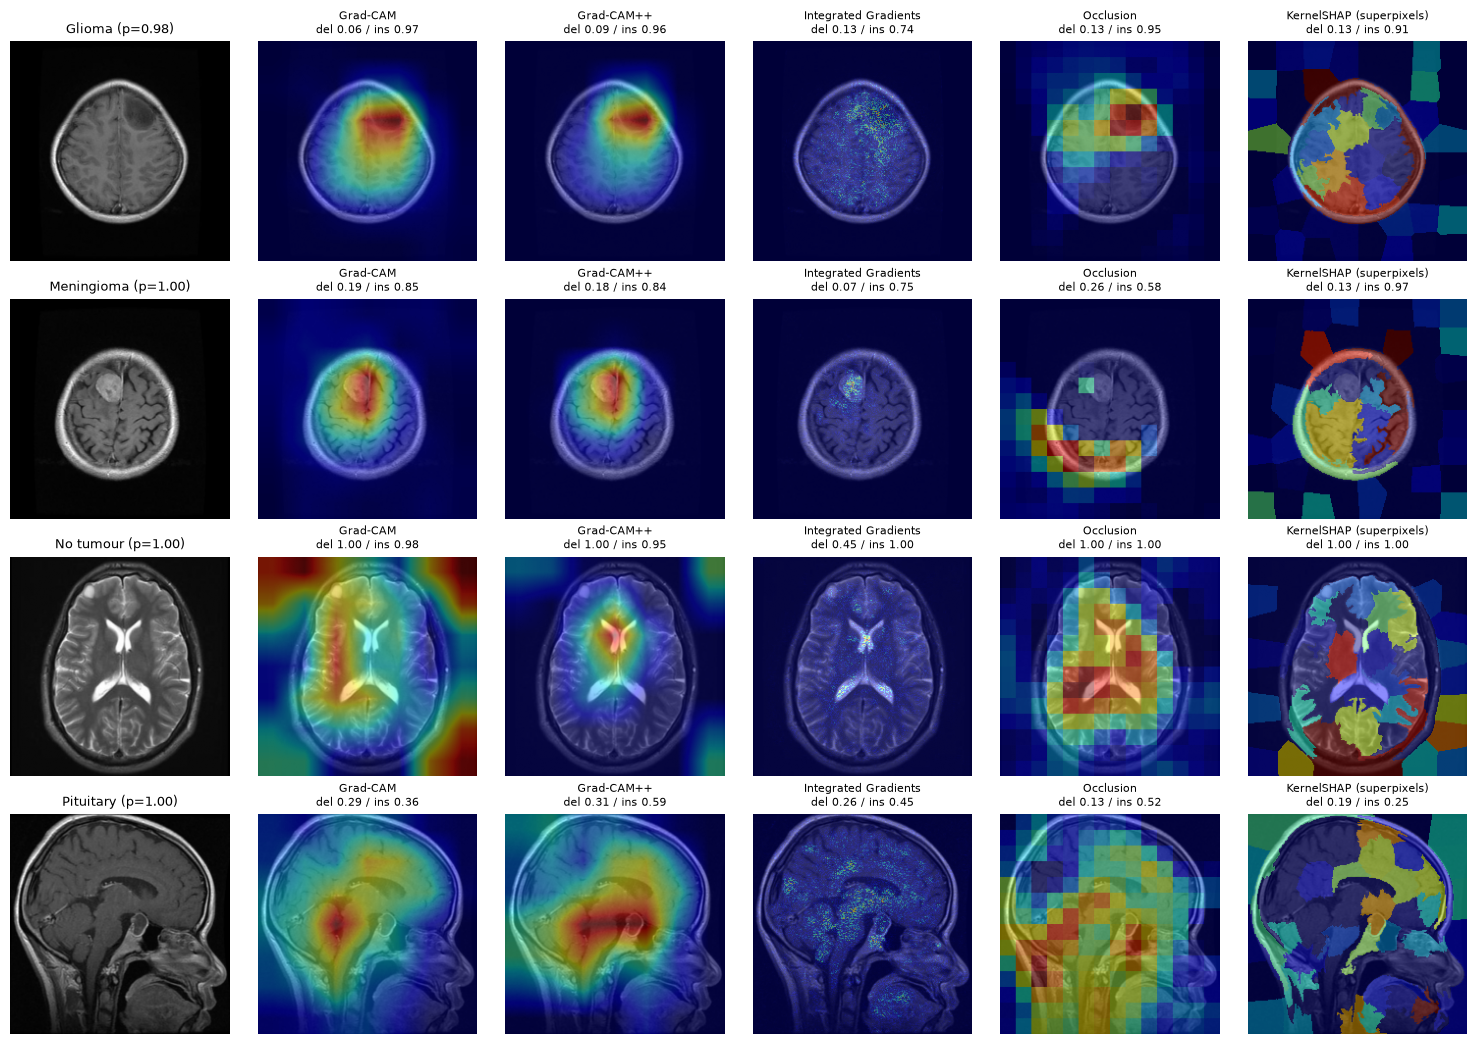

In [4]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10.5))
for i, c in enumerate(CLASSES):
    r = pred[(pred.true == c) & (pred.pred == c)].sample(1, random_state=3).iloc[0]
    x = torch.from_numpy(load_gray_square(str(root / r.relpath), 224)).float().div(255)[None, None]
    k = CLASSES.index(r.pred)
    axes[i, 0].imshow(x[0, 0], cmap="gray"); axes[i, 0].set_title(f"{CLASS_LABELS[c]} (p={r.confidence:.2f})", fontsize=9)
    for j, mth in enumerate(METHODS):
        s = explain(gm, x, k, mth)
        d, ins = deletion_insertion(gm, x, k, s)
        axes[i, j + 1].imshow(x[0, 0], cmap="gray"); axes[i, j + 1].imshow(s, cmap="jet", alpha=0.45)
        axes[i, j + 1].set_title(f"{METHOD_LABELS[mth]}\ndel {d:.2f} / ins {ins:.2f}", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

### Full study (100 test images, 25 per class; 12 images for the sanity check)

In [5]:
FORCE_XAI = False
if FORCE_XAI or not Path("results/xai/faithfulness_summary.csv").exists():
    subprocess.run([sys.executable, "scripts/run_xai.py"], check=True)
faith = pd.read_csv("results/xai/faithfulness_per_image.csv")
display(faith.groupby("method")[["deletion_auc", "insertion_auc", "inside_foreground"]].agg(["mean", "std"]).round(3))
san = pd.read_csv("results/xai/sanity_cascading_randomisation.csv")
display(san.groupby(["method", "stage"], sort=False).spearman.mean().unstack().round(3))
display(pd.read_csv("results/xai/method_agreement_spearman.csv", index_col=0).round(3))

deletion_auc        insertion_auc         \
                             mean    std          mean    std   
method                                                          
gradcam                     0.442  0.359         0.828  0.215   
gradcampp                   0.454  0.346         0.823  0.217   
integrated_gradients        0.260  0.213         0.680  0.259   
kernel_shap                 0.419  0.369         0.764  0.276   
occlusion                   0.387  0.385         0.790  0.254   
random                      0.285  0.106         0.424  0.342   

                     inside_foreground         
                                  mean    std  
method                                         
gradcam                          0.763  0.184  
gradcampp                        0.818  0.212  
integrated_gradients             0.977  0.021  
kernel_shap                      0.734  0.115  
occlusion                        0.833  0.121  
random                           0.579  0.136

stage,classifier,conv_head,blocks.6,blocks.4,blocks.2,conv_stem
method,,,,,,
gradcam,0.265,-0.023,0.151,-0.058,0.024,-0.076
gradcampp,0.911,0.770,0.465,0.406,0.370,0.054
integrated_gradients,0.942,0.937,0.935,0.916,0.898,0.835
occlusion,0.149,0.013,0.194,0.128,0.046,0.023
kernel_shap,0.174,-0.092,0.240,0.111,0.167,0.167


,gradcam,gradcampp,integrated_gradients,occlusion,kernel_shap
gradcam,1.000,0.804,0.412,0.430,0.194
gradcampp,0.804,1.000,0.522,0.434,0.202
integrated_gradients,0.412,0.522,1.000,0.397,0.242
occlusion,0.430,0.434,0.397,1.000,0.232
kernel_shap,0.194,0.202,0.242,0.232,1.000


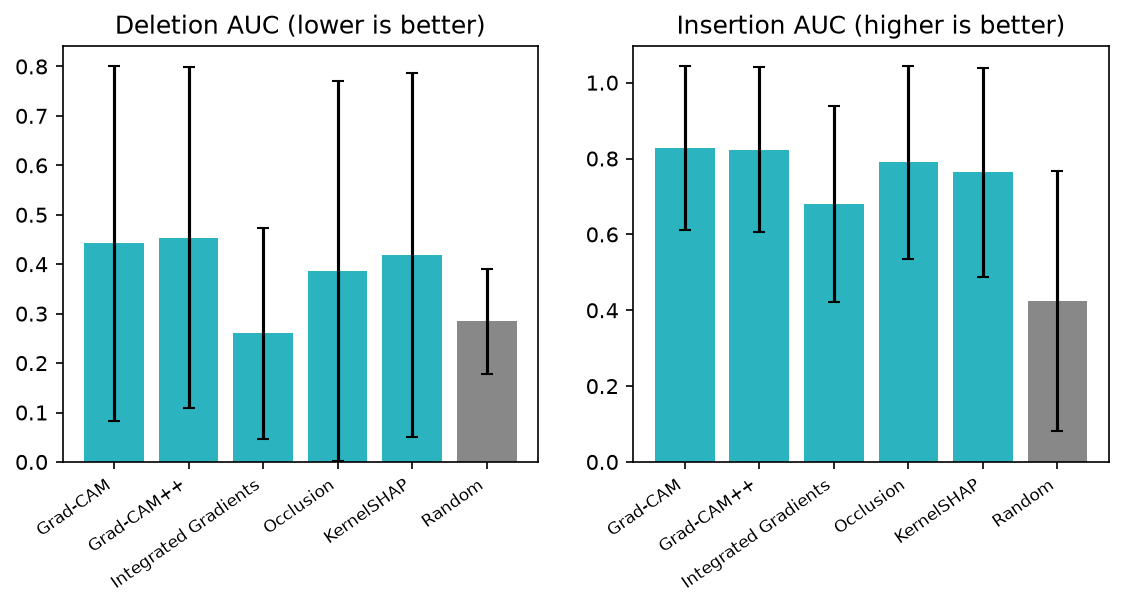

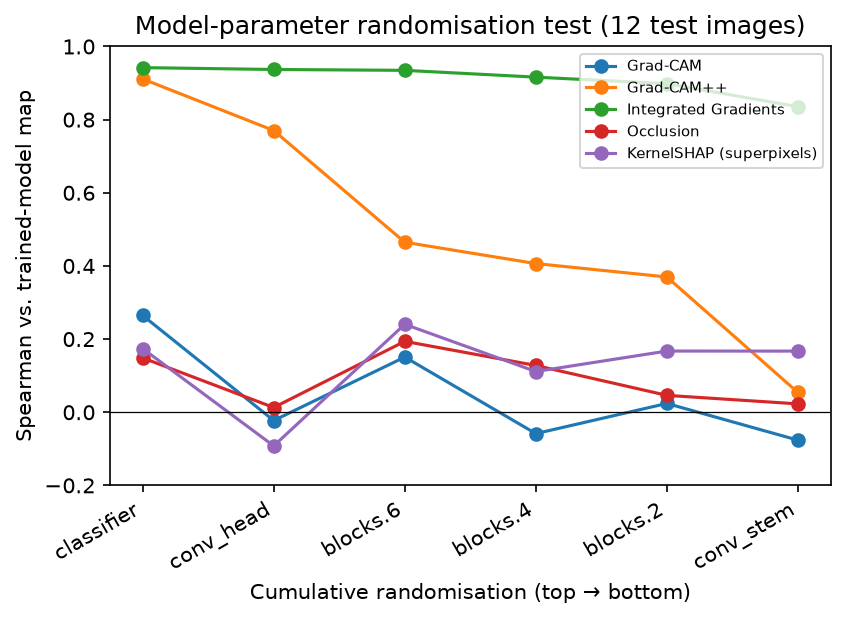

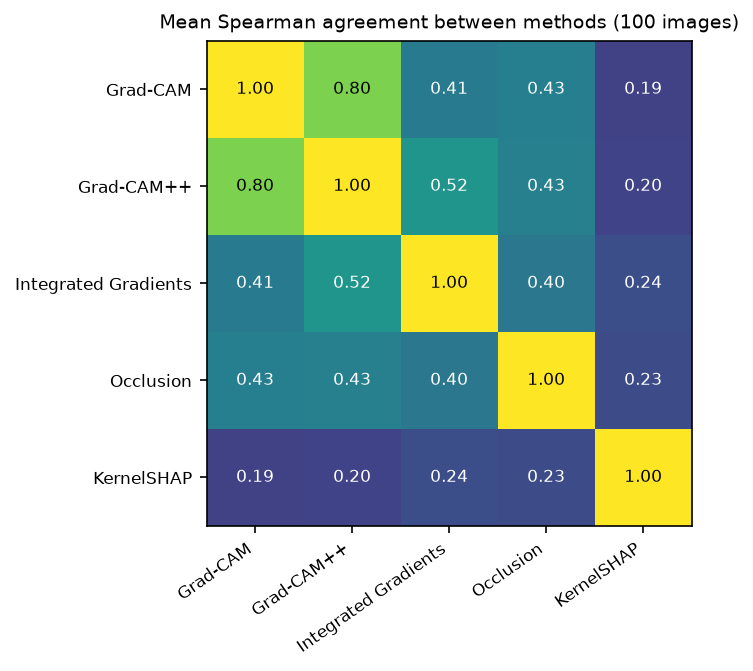

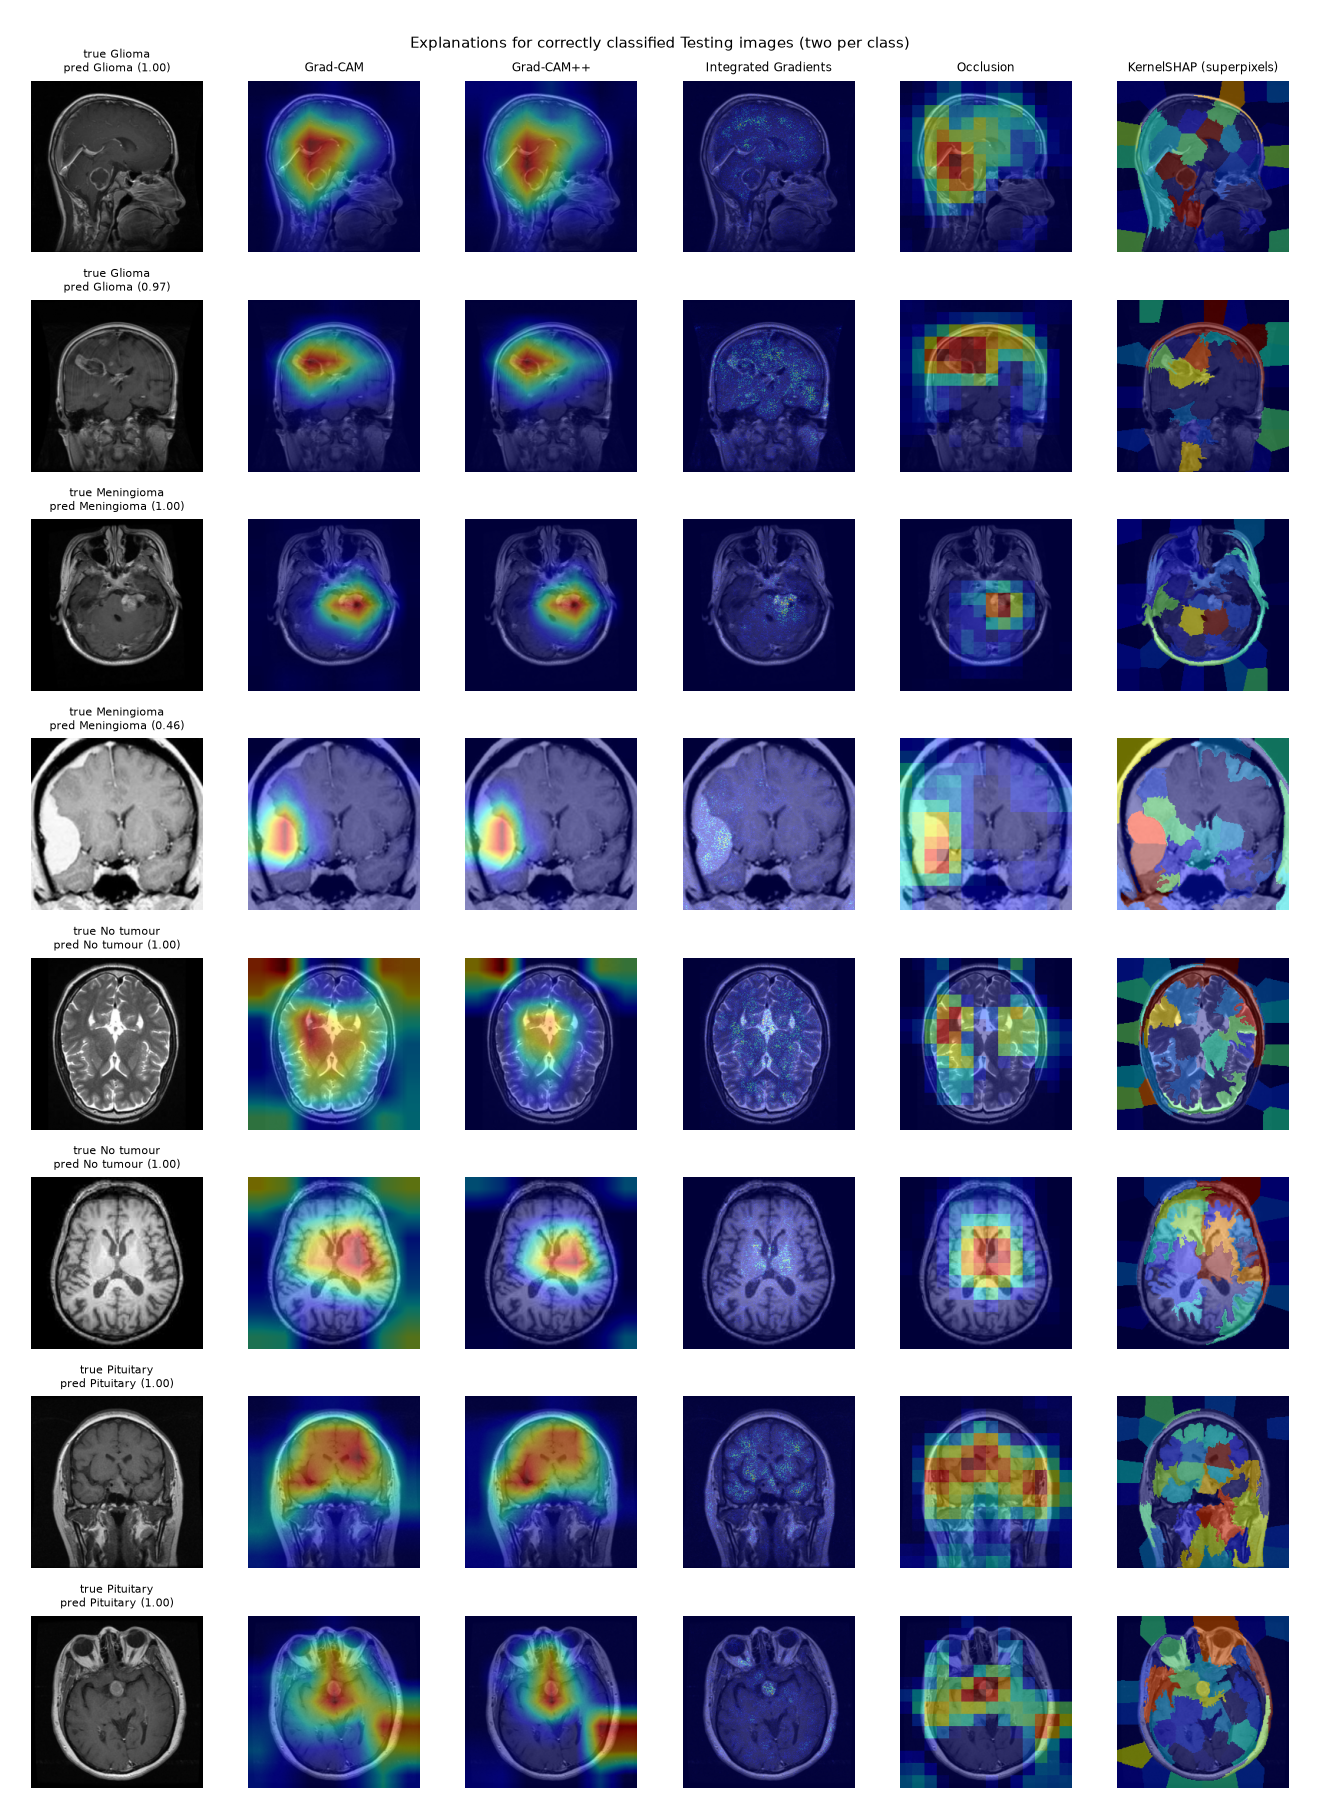

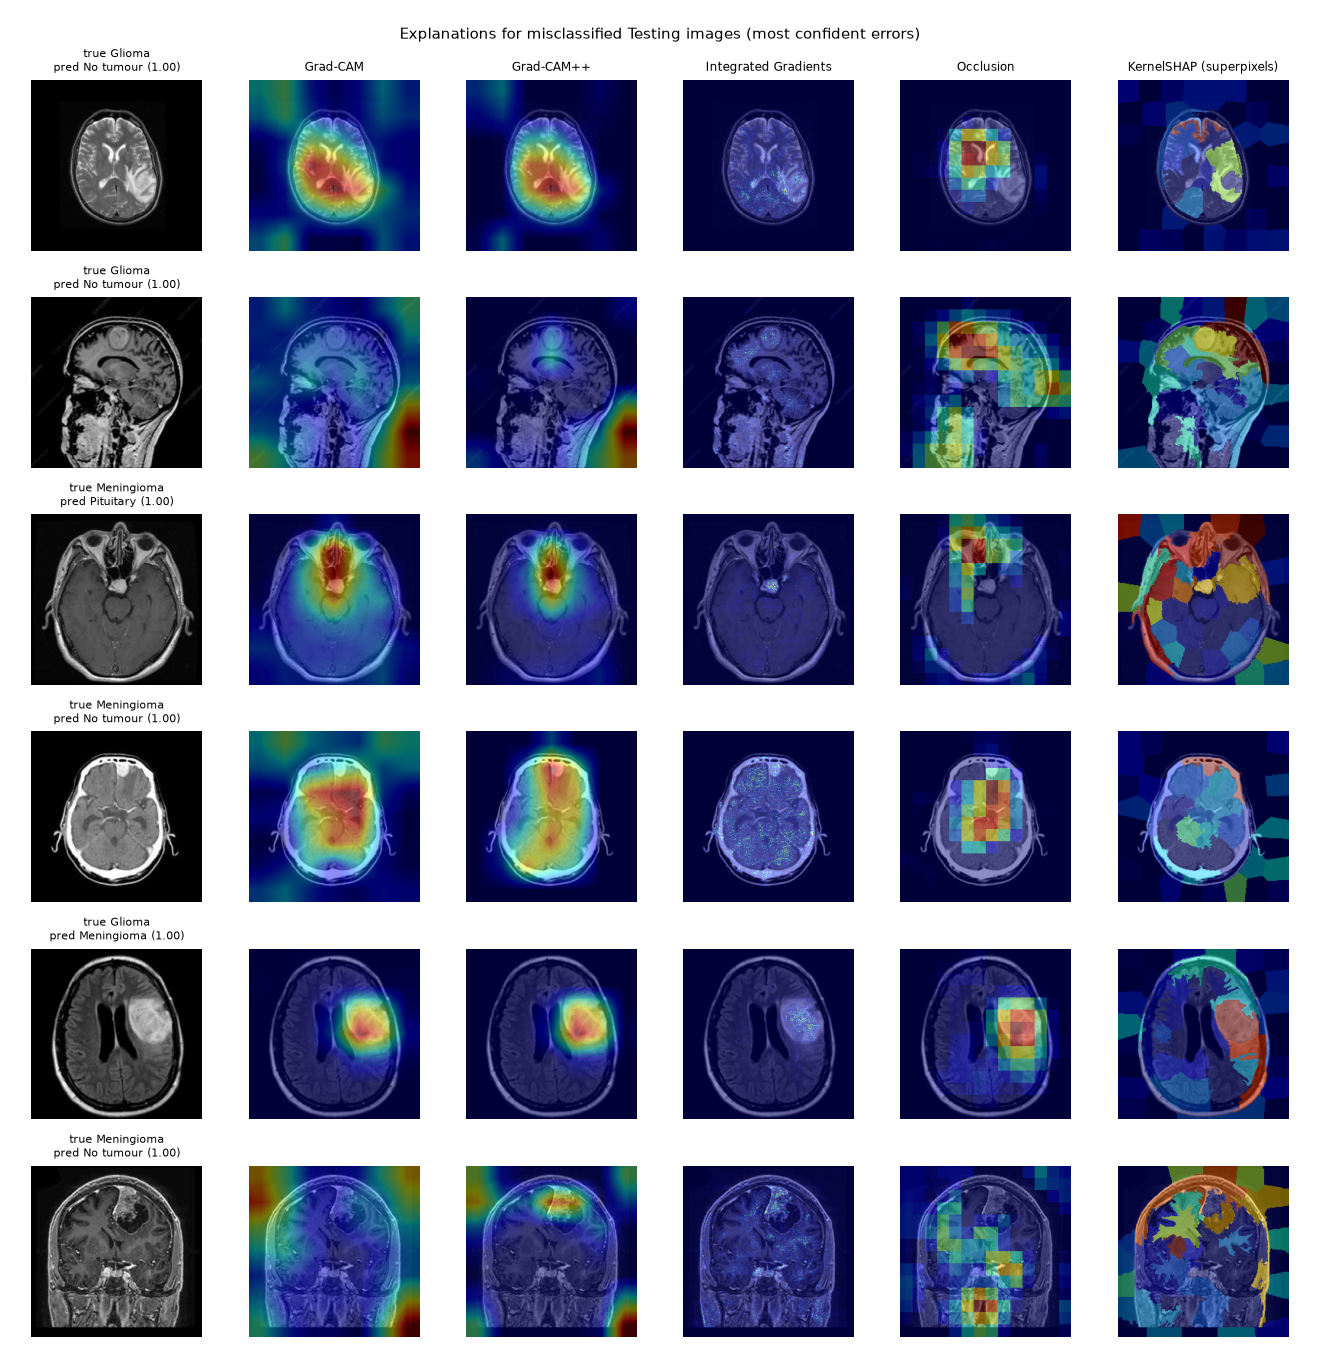

In [6]:
from IPython.display import Image, display
for f in ("xai_faithfulness", "xai_sanity_check", "xai_agreement", "xai_grid_correct", "xai_grid_misclassified"):
    if Path(f"results/figures/{f}.png").exists():
        display(Image(f"results/figures/{f}.png", width=900 if "grid" in f else 620))